In [1]:
!pip install geopandas networkx numpy matplotlib pandas shapely

Nombre total de supports : 863

Aperçu des données :
       TFO Type_suppo_existant       angle    distance  vertex_ind
0  Ext-GL2               arrêt   79.243455    0.000000         0.0
1  Ext-GL2          derivation   39.282313   15.146328         1.0
2  Ext-GL2          alignement  359.321172   56.544198         2.0
3  Ext-GL2          alignement  359.321172   97.942068         3.0
4  Ext-GL2          alignement  359.321172  139.339938         4.0

=== RAPPORT DE CLASSIFICATION ===
        TFO Type_suppo_existant Type_suppo_nouveau  \
0   Ext-GL2               arrêt              arrêt   
1   Ext-GL2          derivation              angle   
2   Ext-GL2          alignement              angle   
3   Ext-GL2          alignement              angle   
4   Ext-GL2          alignement              angle   
5   Ext-GL2          alignement              angle   
6   Ext-GL2          etoilement              angle   
7   Ext-GL2          alignement              angle   
8   Ext-GL2          ali

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18824\1777149965.py:115: RuntimeWarning: invalid value encountered in arccos
  angle = np.degrees(np.arccos(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))))
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18824\1777149965.py:273: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  subset.plot(ax=ax, color=color, markersize=50, label=type_name, alpha=0.7)



Visualisation sauvegardée dans 'classification_supports_grand_lahou.png'

=== STATISTIQUES PAR TYPE DE SUPPORT ===
- angle: 735 supports (85.2%)
- alignement: 63 supports (7.3%)
- derivation: 37 supports (4.3%)
- arrêt: 28 supports (3.2%)

Export CSV sauvegardé dans 'classification_supports_grand_lahou.csv'
Export GeoJSON sauvegardé dans 'classification_supports_grand_lahou.geojson'

=== DÉTECTION DES ÉTOILEMENTS (nœuds centraux) ===
Nombre d'étoilements détectés : 0


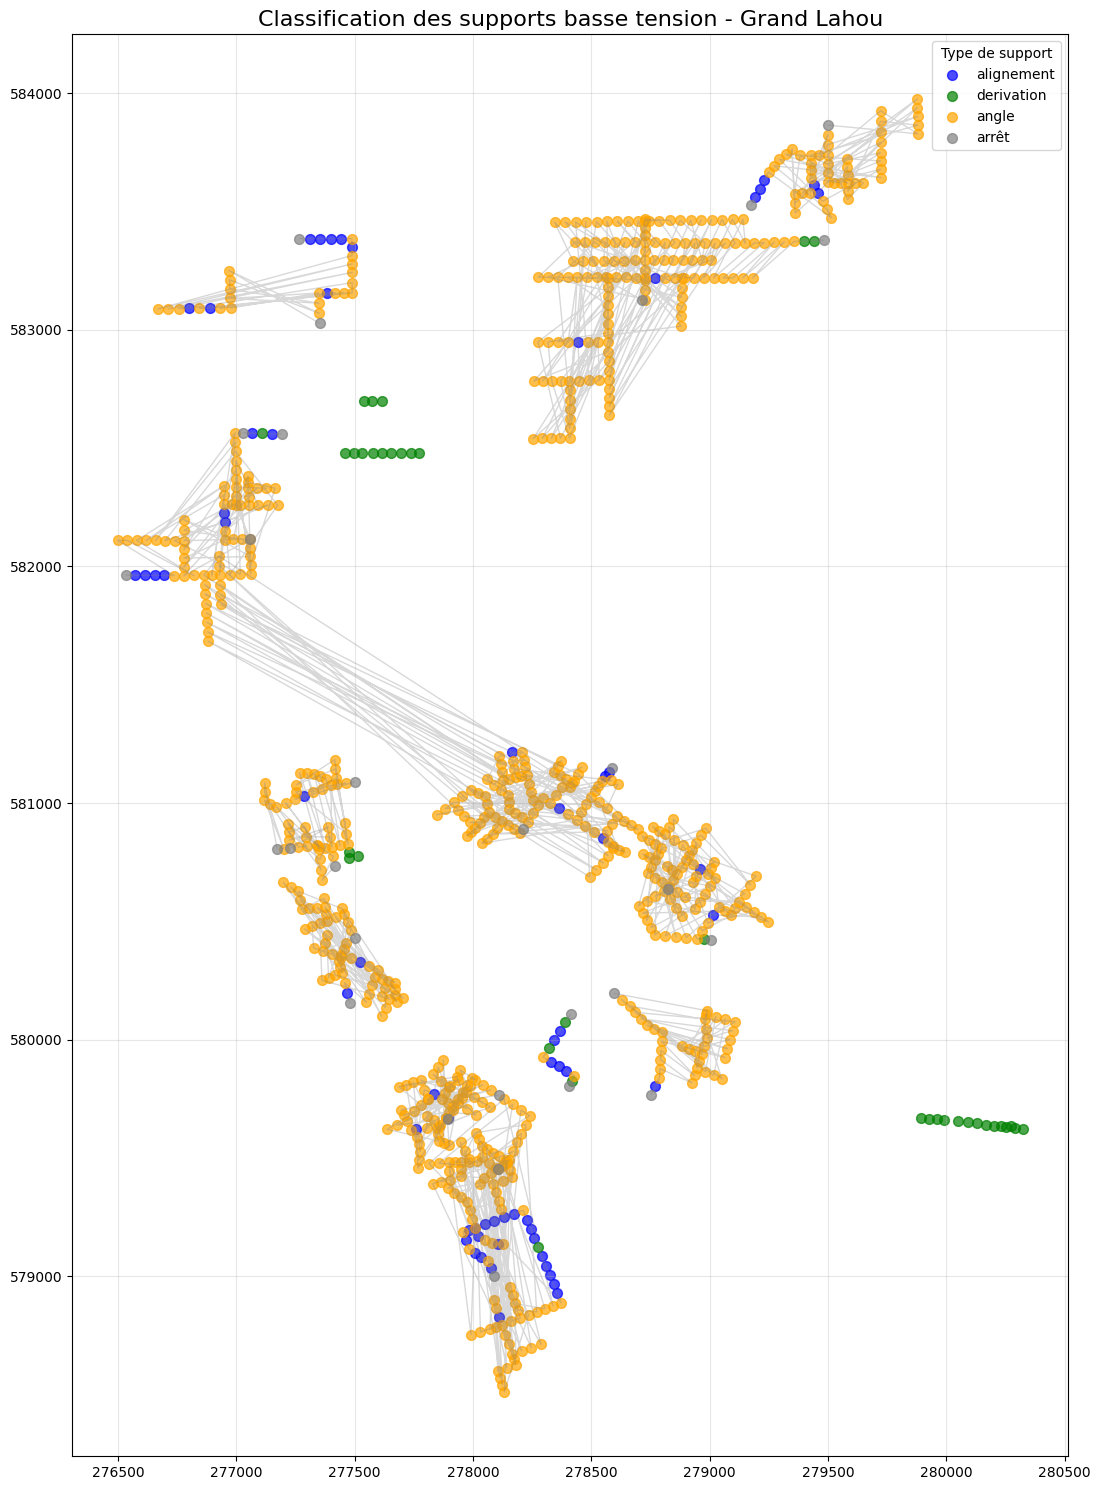

In [3]:
import json
import geopandas as gpd
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString
from collections import defaultdict

# =============================================
# 1. CHARGEMENT ET PRÉTRAITEMENT DES DONNÉES
# =============================================

def load_geojson(file_path):
    """Charge le GeoJSON et extrait les données"""
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    features = []
    for feature in data['features']:
        props = feature['properties']
        geom = feature['geometry']
        features.append({
            'id': props.get('id', ''),
            'TFO': props.get('TFO', ''),
            'Type_suppo_existant': props.get('Type_suppo', ''),
            'coordinates': geom['coordinates'],
            'angle': props.get('angle', None),
            'distance': props.get('distance', None),
            'vertex_ind': props.get('vertex_ind', None),
            'Type': props.get('Type', ''),
            'Sortie': props.get('Sortie', ''),
            'Section': props.get('Section', ''),
            'Ville': props.get('Ville', '')
        })

    return pd.DataFrame(features), data

# Charger les données
df, original_geojson = load_geojson("SupportBT_GrandLahou_Ext_Dens_geojson.geojson")

print(f"Nombre total de supports : {len(df)}")
print("\nAperçu des données :")
print(df[['TFO', 'Type_suppo_existant', 'angle', 'distance', 'vertex_ind']].head())

# =============================================
# 2. CONSTRUCTION DU GRAPHE TOPOLOGIQUE
# =============================================

def build_topology_graph(df):
    """Construire un graphe des connexions entre supports"""
    G = nx.Graph()

    # Ajouter les nœuds (supports)
    for idx, row in df.iterrows():
        G.add_node(idx, **row.to_dict())

    # Connecter les supports en séquence (pour chaque TFO)
    tfo_groups = df.groupby('TFO')
    for tfo, group in tfo_groups:
        # Trier par vertex_ind pour avoir l'ordre de la ligne
        group_sorted = group.sort_values('vertex_ind')
        for i in range(len(group_sorted) - 1):
            node1 = group_sorted.iloc[i].name
            node2 = group_sorted.iloc[i + 1].name
            G.add_edge(node1, node2)

    return G

# Construire le graphe
G = build_topology_graph(df)

# =============================================
# 3. CLASSIFICATION DES TYPES DE SUPPORTS
# =============================================

def classify_support_types(G, df, angle_threshold=10, min_branch_angle=30):
    """
    Classifie les supports en :
    - alignement
    - dérivation
    - angle
    - étoilement
    - arrêt (terminal)

    Args:
        G: graphe NetworkX
        df: DataFrame des supports
        angle_threshold: seuil pour considérer un angle (en degrés)
        min_branch_angle: seuil pour considérer une branche comme significative

    Returns:
        DataFrame avec la nouvelle classification
    """
    classifications = {}
    degrees = dict(G.degree())

    # Calculer les angles entre segments pour détecter les changements de direction
    def calculate_angles(G):
        angles = {}
        for node in G.nodes():
            if degrees[node] == 2:  # Seuls les nœuds avec 2 connexions peuvent avoir un angle
                neighbors = list(G.neighbors(node))
                if len(neighbors) == 2:
                    # Récupérer les coordonnées
                    x1, y1 = G.nodes[neighbors[0]]['coordinates']
                    x2, y2 = G.nodes[node]['coordinates']
                    x3, y3 = G.nodes[neighbors[1]]['coordinates']

                    # Vecteurs
                    v1 = np.array([x2 - x1, y2 - y1])
                    v2 = np.array([x3 - x2, y3 - y2])

                    # Angle en degrés (entre 0 et 180)
                    angle = np.degrees(np.arccos(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))))
                    angles[node] = angle
        return angles

    node_angles = calculate_angles(G)

    # Classification principale
    for node in G.nodes():
        degree = degrees[node]
        props = G.nodes[node]
        angle = node_angles.get(node, None)
        tfo = props['TFO']

        # 1. Nœuds terminaux (arrêt)
        if degree == 1:
            classifications[node] = {
                'type': 'arrêt',
                'description': 'Nœud terminal (fin de ligne)',
                'raison': 'Degré = 1'
            }

        # 2. Nœuds en alignement (ligne droite)
        elif degree == 2 and angle is not None and angle < angle_threshold:
            classifications[node] = {
                'type': 'alignement',
                'description': f'Ligne droite (angle={angle:.1f}°)',
                'raison': f'Angle < {angle_threshold}°'
            }

        # 3. Nœuds avec angle significatif
        elif degree == 2 and angle is not None and angle >= angle_threshold:
            classifications[node] = {
                'type': 'angle',
                'description': f'Changement de direction ({angle:.1f}°)',
                'raison': f'Angle ≥ {angle_threshold}°'
            }

        # 4. Nœuds avec plusieurs branches (intersection ou étoilement)
        elif degree >= 3:
            # Vérifier si c'est un étoilement (plusieurs branches avec changement de direction)
            neighbors = list(G.neighbors(node))
            branch_angles = []

            for neighbor in neighbors:
                if neighbor in node_angles:
                    branch_angles.append(node_angles[neighbor])

            # Si la majorité des branches ont des angles significatifs, c'est probablement un étoilement
            significant_branches = sum(1 for a in branch_angles if a >= min_branch_angle)
            if significant_branches >= 2:
                classifications[node] = {
                    'type': 'étoilement',
                    'description': f'Nœud central avec {degree} branches (angles: {[f"{a:.1f}°" for a in branch_angles]})',
                    'raison': f'Degré ≥ 3 et {significant_branches} branches avec angle ≥ {min_branch_angle}°'
                }
            else:
                classifications[node] = {
                    'type': 'intersection',
                    'description': f'Intersection de {degree} lignes',
                    'raison': f'Degré ≥ 3'
                }

        # 5. Dérivations (branches secondaires)
        else:
            classifications[node] = {
                'type': 'derivation',
                'description': 'Dérivation ou branchement secondaire',
                'raison': 'Autre cas'
            }

    # Créer le DataFrame de résultats
    results = []
    for node, classification in classifications.items():
        props = G.nodes[node]
        results.append({
            'id': props['id'],
            'TFO': props['TFO'],
            'Type_suppo_existant': props['Type_suppo_existant'],
            'Type_suppo_nouveau': classification['type'],
            'Description': classification['description'],
            'Raison': classification['raison'],
            'Degré': degrees[node],
            'Angle': node_angles.get(node, None),
            'Coordinates': props['coordinates'],
            'vertex_ind': props['vertex_ind']
        })

    return pd.DataFrame(results)

# Classifier les supports
classification_df = classify_support_types(G, df)

print("\n=== RAPPORT DE CLASSIFICATION ===")
print(classification_df[['TFO', 'Type_suppo_existant', 'Type_suppo_nouveau', 'Description', 'Degré', 'Angle']].head(20))

# =============================================
# 4. ANALYSE DES DIFFÉRENCES AVEC LA CLASSIFICATION EXISTANTE
# =============================================

def analyze_differences(classification_df):
    """Compare la classification existante avec la nouvelle"""
    # Ajouter une colonne de comparaison
    classification_df['Différence'] = classification_df.apply(
        lambda row: '✅ OK' if row['Type_suppo_existant'] == row['Type_suppo_nouveau'] else '⚠️ Différent',
        axis=1
    )

    # Statistiques
    stats = classification_df['Différence'].value_counts()
    print("\n=== STATISTIQUES DE CLASSIFICATION ===")
    print(f"Total supports : {len(classification_df)}")
    print(f"Classifications identiques : {stats.get('✅ OK', 0)} ({stats.get('✅ OK', 0)/len(classification_df)*100:.1f}%)")
    print(f"Classifications différentes : {stats.get('⚠️ Différent', 0)} ({stats.get('⚠️ Différent', 0)/len(classification_df)*100:.1f}%)")

    # Liste des différences
    differences = classification_df[classification_df['Différence'] == '⚠️ Différent']
    if not differences.empty:
        print("\n=== LISTE DES DIFFÉRENCES ===")
        print(differences[['TFO', 'Type_suppo_existant', 'Type_suppo_nouveau', 'Description']])

    return classification_df

classification_df = analyze_differences(classification_df)

# =============================================
# 5. VISUALISATION DES RÉSULTATS
# =============================================

def visualize_classification(df, classification_df):
    """Visualise la classification sur une carte"""
    # Créer un GeoDataFrame
    gdf = gpd.GeoDataFrame(
        df,
        geometry=[Point(coord) for coord in df['coordinates']],
        crs="EPSG:32630"
    )

    # Ajouter la nouvelle classification
    gdf['Type_nouveau'] = classification_df['Type_suppo_nouveau']

    # Filtrer pour la visualisation
    gdf_plot = gdf[gdf['Type_nouveau'].isin(['alignement', 'derivation', 'angle', 'étoilement', 'arrêt'])]

    # Créer une figure
    fig, ax = plt.subplots(figsize=(15, 15))

    # Couleurs par type
    color_map = {
        'alignement': 'blue',
        'derivation': 'green',
        'angle': 'orange',
        'étoilement': 'red',
        'arrêt': 'gray'
    }

    # Dessiner les points
    for type_name, color in color_map.items():
        subset = gdf_plot[gdf_plot['Type_nouveau'] == type_name]
        subset.plot(ax=ax, color=color, markersize=50, label=type_name, alpha=0.7)

    # Ajouter les connexions (lignes)
    for tfo, group in gdf.groupby('TFO'):
        group_sorted = group.sort_values('vertex_ind')
        coords = group_sorted['geometry'].tolist()
        if len(coords) > 1:
            line = LineString(coords)
            gpd.GeoSeries([line]).plot(ax=ax, color='gray', linewidth=1, alpha=0.3)

    # Légende et titre
    ax.set_title('Classification des supports basse tension - Grand Lahou', fontsize=16)
    ax.legend(title='Type de support')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    # Sauvegarder la visualisation
    plt.savefig('classification_supports_grand_lahou.png', dpi=300, bbox_inches='tight')
    print("\nVisualisation sauvegardée dans 'classification_supports_grand_lahou.png'")

    # Afficher les statistiques par type
    type_counts = classification_df['Type_suppo_nouveau'].value_counts()
    print("\n=== STATISTIQUES PAR TYPE DE SUPPORT ===")
    for type_name, count in type_counts.items():
        print(f"- {type_name}: {count} supports ({count/len(classification_df)*100:.1f}%)")

# Visualiser les résultats
visualize_classification(df, classification_df)

# =============================================
# 6. EXPORT DES RÉSULTATS
# =============================================

def export_results(classification_df, filename):
    """Exporte les résultats en CSV et GeoJSON"""
    # Export CSV
    classification_df.to_csv(filename + '.csv', index=False)
    print(f"\nExport CSV sauvegardé dans '{filename}.csv'")

    # Export GeoJSON
    gdf = gpd.GeoDataFrame(
        classification_df,
        geometry=[Point(coord) for coord in classification_df['Coordinates']],
        crs="EPSG:32630"
    )

    # Préparer le GeoJSON
    geojson_features = []
    for _, row in gdf.iterrows():
        geojson_features.append({
            "type": "Feature",
            "geometry": {
                "type": "Point",
                "coordinates": [row['Coordinates'][0], row['Coordinates'][1]]
            },
            "properties": {
                "id": row['id'],
                "TFO": row['TFO'],
                "Type_suppo_existant": row['Type_suppo_existant'],
                "Type_suppo_nouveau": row['Type_suppo_nouveau'],
                "Description": row['Description'],
                "Degré": row['Degré'],
                "Angle": row['Angle'],
                "Raison": row['Raison'],
                "vertex_ind": row['vertex_ind']
            }
        })

    geojson_output = {
        "type": "FeatureCollection",
        "features": geojson_features,
        "crs": {"type": "name", "properties": {"name": "urn:ogc:def:crs:EPSG::32630"}}
    }

    with open(filename + '.geojson', 'w', encoding='utf-8') as f:
        json.dump(geojson_output, f, indent=2, ensure_ascii=False)

    print(f"Export GeoJSON sauvegardé dans '{filename}.geojson'")

# Exporter les résultats
export_results(classification_df, "classification_supports_grand_lahou")

# =============================================
# 7. ANALYSE SUPPLÉMENTAIRE : DÉTECTION DES ÉTOILEMENTS
# =============================================

def detect_star_structures(classification_df, min_branches=3):
    """Détecte les structures en étoile (nœuds centraux avec plusieurs branches)"""
    star_nodes = classification_df[
        (classification_df['Type_suppo_nouveau'] == 'étoilement') &
        (classification_df['Degré'] >= min_branches)
    ]

    print("\n=== DÉTECTION DES ÉTOILEMENTS (nœuds centraux) ===")
    print(f"Nombre d'étoilements détectés : {len(star_nodes)}")

    if not star_nodes.empty:
        print("\nListe des nœuds centraux (étoilements) :")
        print(star_nodes[['TFO', 'id', 'Degré', 'Description']])

        # Calculer la distance moyenne entre les branches
        star_nodes['branch_distances'] = star_nodes.apply(
            lambda row: [classification_df.loc[classification_df['TFO'] == row['TFO'] &
                                              classification_df['vertex_ind'] == vi, 'distance'].values[0]
                        for vi in range(len(classification_df[classification_df['TFO'] == row['TFO']]))],
            axis=1
        )

    return star_nodes

star_nodes = detect_star_structures(classification_df)


In [ ]:
# Fusionner avec les informations des nœuds
df_classification = pd.merge(
    df_nodes,
    df_angles,
    on='node_id',
    how='left',
    suffixes=('_node', '_angle')
)

# Garantir l'existence des colonnes après fusion
for col in ['type_node', 'type_angle']:
    if col not in df_classification.columns:
        df_classification[col] = np.nan

# Remplir les types manquants (nœuds terminaux)
df_classification['type'] = df_classification.apply(
    lambda row: 'terminal' if row.get('type_node') in ['début', 'fin'] else (
        row['type_angle'] if pd.notna(row.get('type_angle')) else row.get('type_node', 'unknown')
    ),
    axis=1
)


In [12]:
import json
import geopandas as gpd
import networkx as nx
import numpy as np
import pandas as pd
from shapely.geometry import Point, LineString
from collections import defaultdict
import matplotlib.pyplot as plt
from math import atan2, degrees, sqrt

# =============================================
# 1. CHARGEMENT ET PRÉTRAITEMENT DES DONNÉES
# =============================================

def load_lignes_geojson(file_path):
    """Charge le GeoJSON des lignes et extrait les segments"""
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    features = []
    for feature in data['features']:
        props = feature['properties']
        geom = feature['geometry']

        # Convertir MultiLineString en LineString
        if geom['type'] == 'MultiLineString':
            coords = geom['coordinates'][0]  # Prendre la première ligne
        else:
            coords = geom['coordinates']

        features.append({
            'id': props.get('id', ''),
            'TFO': props.get('TFO', ''),
            'Type': props.get('Type', ''),
            'Type_2': props.get('Type_2', ''),
            'Longueur': props.get('Longueur', 0),
            'geometry': LineString(coords)
        })

    return gpd.GeoDataFrame(features, crs="EPSG:4326")

# Charger les données
gdf_lignes = load_lignes_geojson("LigneBT_GrandLahou_Ext_Dens_geojson.geojson")

print(f"✅ Données chargées avec succès!")
print(f"📊 Nombre total de lignes : {len(gdf_lignes)}")
print(f"📍 Système de coordonnées : {gdf_lignes.crs}")
print("\n📋 Aperçu des données :")
print(gdf_lignes[['id', 'TFO', 'Type', 'Type_2', 'Longueur']].head())

# =============================================
# 2. EXTRACTION DES NŒUDS (POINTS DE CONNEXION)
# =============================================

def extract_nodes(gdf):
    """Extrait tous les nœuds de connexion entre lignes"""
    nodes = []
    node_ids = []
    node_coords = []

    for idx, row in gdf.iterrows():
        coords = list(row.geometry.coords)

        # Ajouter le début de la ligne
        start_node = coords[0]
        if start_node not in node_ids:
            node_ids.append(start_node)
            node_coords.append(start_node)
            nodes.append({
                'node_id': len(node_ids)-1,
                'coords': start_node,
                'type': 'début',
                'tfo': row.TFO,
                'ligne_ids': [idx]
            })
        else:
            idx_existing = node_ids.index(start_node)
            nodes[idx_existing]['ligne_ids'].append(idx)

        # Ajouter la fin de la ligne
        end_node = coords[-1]
        if end_node not in node_ids:
            node_ids.append(end_node)
            node_coords.append(end_node)
            nodes.append({
                'node_id': len(node_ids)-1,
                'coords': end_node,
                'type': 'fin',
                'tfo': row.TFO,
                'ligne_ids': [idx]
            })
        else:
            idx_existing = node_ids.index(end_node)
            nodes[idx_existing]['ligne_ids'].append(idx)

    return pd.DataFrame(nodes), node_coords

df_nodes, node_coords = extract_nodes(gdf_lignes)

print(f"\n🔍 Extraction des nœuds terminée!")
print(f"📍 Nombre total de nœuds extraits : {len(df_nodes)}")
print("\nRépartition initiale des nœuds :")
print(df_nodes['type'].value_counts())

# =============================================
# 3. CONSTRUCTION DU GRAPHE TOPOLOGIQUE
# =============================================

def build_topology_graph(gdf_lignes, node_coords):
    """Construit un graphe topologique des connexions entre lignes"""
    G = nx.Graph()

    # Ajouter les nœuds au graphe
    for node_id, coords in enumerate(node_coords):
        G.add_node(node_id, pos=coords)

    # Ajouter les arêtes (connexions entre nœuds)
    for idx, row in gdf_lignes.iterrows():
        coords = list(row.geometry.coords)
        start_id = node_coords.index(coords[0])
        end_id = node_coords.index(coords[-1])
        G.add_edge(start_id, end_id, ligne_id=idx)

    return G

G = build_topology_graph(gdf_lignes, node_coords)

# =============================================
# 4. CALCUL DES ANGLES ET CLASSIFICATION
# =============================================

def haversine_distance(coord1, coord2):
    """Calcule la distance en mètres entre deux points WGS84"""
    # Rayon de la Terre en mètres
    R = 6371000

    lat1, lon1 = coord1
    lat2, lon2 = coord2

    # Convertir en radians
    lat1_rad = np.radians(lat1)
    lat2_rad = np.radians(lat2)
    delta_lat = np.radians(lat2 - lat1)
    delta_lon = np.radians(lon2 - lon1)

    # Formule de Haversine
    a = np.sin(delta_lat/2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(delta_lon/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
    distance = R * c

    return distance

def calculate_angles(gdf_lignes, node_coords):
    """Calcule les angles de changement de direction pour chaque nœud"""
    angle_data = []

    for node_id, coords in enumerate(node_coords):
        connected_lines = []
        for neighbor in G.neighbors(node_id):
            line_id = None
            for edge in G.edges(node_id):
                if edge[1] == neighbor:
                    line_id = G.edges[edge]['ligne_id']
                    break
            if line_id is not None:
                connected_lines.append((line_id, neighbor))

        if len(connected_lines) < 2:
            angle_data.append({
                'node_id': node_id,
                'angle': None,
                'type': 'terminal',
                'degree': len(connected_lines)
            })
            continue

        # Trouver les deux lignes connectées
        line1_id, other_node1 = connected_lines[0]
        line2_id, other_node2 = connected_lines[1]

        # Obtenir les coordonnées des lignes
        line1_coords = list(gdf_lignes.iloc[line1_id].geometry.coords)
        line2_coords = list(gdf_lignes.iloc[line2_id].geometry.coords)

        # Trouver le point de connexion dans chaque ligne
        if line1_coords[0] == coords:
            p1_prev = None
            p1 = line1_coords[1]
        else:
            p1_prev = line1_coords[-2]
            p1 = line1_coords[-1]

        if line2_coords[0] == coords:
            p2_prev = None
            p2 = line2_coords[1]
        else:
            p2_prev = line2_coords[-2]
            p2 = line2_coords[-1]

        # Calculer les vecteurs en coordonnées géographiques
        if p1_prev:
            v1 = np.array([p1[0]-p1_prev[0], p1[1]-p1_prev[1]])
        else:
            v1 = np.array([p1[0]-coords[0], p1[1]-coords[1]])

        if p2_prev:
            v2 = np.array([p2[0]-p2_prev[0], p2[1]-p2_prev[1]])
        else:
            v2 = np.array([p2[0]-coords[0], p2[1]-coords[1]])

        # Calculer l'angle en degrés
        dot_product = np.dot(v1, v2)
        magnitude_v1 = np.sqrt(v1[0]**2 + v1[1]**2)
        magnitude_v2 = np.sqrt(v2[0]**2 + v2[1]**2)

        if magnitude_v1 > 0 and magnitude_v2 > 0:
            cos_angle = dot_product / (magnitude_v1 * magnitude_v2)
            # Limiter la valeur pour éviter les erreurs d'arrondi
            cos_angle = np.clip(cos_angle, -1.0, 1.0)
            angle_rad = np.arccos(cos_angle)
            angle_deg = np.degrees(angle_rad)
        else:
            angle_deg = 0

        # Déterminer le type de support
        if len(connected_lines) == 2:
            if angle_deg > 15:  # Seuil pour considérer comme angle
                support_type = 'angle'
            else:
                support_type = 'alignement'
        else:
            support_type = 'etoilement'

        angle_data.append({
            'node_id': node_id,
            'angle': angle_deg,
            'type': support_type,
            'degree': len(connected_lines)
        })

    return pd.DataFrame(angle_data)

df_angles = calculate_angles(gdf_lignes, node_coords)

# Fusionner avec les informations des nœuds
df_classification = pd.merge(df_nodes, df_angles, on='node_id', how='left')

# Remplir les types manquants (nœuds terminaux)
df_classification['type'] = df_classification.apply(
    lambda row: 'terminal' if row['type'] == 'début' or row['type'] == 'fin' else row['type_y'],
    axis=1
)

# =============================================
# 5. GÉNÉRATION DU RAPPORT FINAL
# =============================================

def generate_classification_report(df_classification, gdf_lignes):
    """Génère un rapport détaillé de classification"""
    report = []

    for _, row in df_classification.iterrows():
        # Trouver les TFO associés
        tfo_list = list(set([gdf_lignes.iloc[line_id].TFO for line_id in row['ligne_ids']]))

        report.append({
            'node_id': row['node_id'],
            'coords': row['coords'],
            'type': row['type'],
            'degree': row['degree'] if 'degree' in row else len(row['ligne_ids']),
            'angle': row['angle'] if 'angle' in row else None,
            'tfo': ', '.join(tfo_list),
            'ligne_ids': row['ligne_ids'],
            'num_lignes': len(row['ligne_ids'])
        })

    return pd.DataFrame(report)

df_report = generate_classification_report(df_classification, gdf_lignes)

# =============================================
# 6. VISUALISATION DES RÉSULTATS
# =============================================

def visualize_classification(gdf_lignes, df_report):
    """Visualise les différents types de supports"""
    plt.figure(figsize=(15, 15))

    # Dessiner les lignes
    for idx, row in gdf_lignes.iterrows():
        x, y = row.geometry.xy
        plt.plot(x, y, 'gray', alpha=0.5, linewidth=1)

    # Colorer les nœuds selon leur type
    colors = {
        'terminal': 'red',
        'alignement': 'green',
        'derivation': 'blue',
        'angle': 'orange',
        'etoilement': 'purple'
    }

    for _, row in df_report.iterrows():
        plt.scatter(
            row['coords'][0], row['coords'][1],
            color=colors.get(row['type'], 'gray'),
            s=100 if row['type'] == 'etoilement' else 50,
            label=row['type'] if row['type'] not in ['terminal'] else 'arrêt',
            alpha=0.8
        )

    plt.title("Classification des supports BT - Grand Lahou", fontsize=16)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")

    # Créer une légende
    handles = []
    for type_name, color in colors.items():
        if type_name != 'terminal':
            handles.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color,
                                    markersize=10, label=type_name))

    plt.legend(handles=handles, loc='upper right')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("classification_supports_grand_lahou.png", dpi=300)
    plt.show()

visualize_classification(gdf_lignes, df_report)

# =============================================
# 7. EXPORT DES RÉSULTATS
# =============================================

# Créer un GeoJSON des nœuds classifiés
nodes_gdf = gpd.GeoDataFrame(
    geometry=[Point(coords) for coords in node_coords],
    crs="EPSG:4326"
)

nodes_gdf['node_id'] = df_report['node_id']
nodes_gdf['type'] = df_report['type']
nodes_gdf['angle'] = df_report['angle']
nodes_gdf['degree'] = df_report['degree']
nodes_gdf['tfo'] = df_report['tfo']
nodes_gdf['ligne_ids'] = df_report['ligne_ids'].apply(lambda x: ','.join(map(str, x)))

nodes_gdf.to_file("classification_supports_grand_lahou.geojson", driver="GeoJSON")

# Exporter le rapport CSV
df_report.to_csv("classification_supports_grand_lahou.csv", index=False)

# =============================================
# 8. ANALYSE STATISTIQUE
# =============================================

print("\n" + "="*80)
print("📊 RAPPORT FINAL DE CLASSIFICATION")
print("="*80)
print(f"\n📈 Nombre total de nœuds analysés : {len(df_report)}")

print("\n📊 Répartition par type de support :")
type_counts = df_report['type'].value_counts()
for type_name, count in type_counts.items():
    print(f"- {type_name.capitalize()}: {count} ({count/len(df_report)*100:.1f}%)")

print("\n📌 Exemple de classification :")
print(df_report[['node_id', 'type', 'degree', 'angle', 'tfo']].head(10))

print("\n📊 Statistiques sur les angles :")
angle_df = df_report[df_report['angle'].notna()]
if len(angle_df) > 0:
    print(f"- Angle moyen: {angle_df['angle'].mean():.2f}°")
    print(f"- Angle minimum: {angle_df['angle'].min():.2f}°")
    print(f"- Angle maximum: {angle_df['angle'].max():.2f}°")
    print(f"- Écart-type: {angle_df['angle'].std():.2f}°")

print("\n🔝 Top 5 des tronçons avec le plus de nœuds :")
tfo_counts = df_report.groupby('tfo').size().sort_values(ascending=False)
print(tfo_counts.head(5))

# =============================================
# 9. VÉRIFICATION DE LA TOPOLOGIE
# =============================================

print("\n" + "="*80)
print("🔍 VÉRIFICATION DE LA TOPOLOGIE")
print("="*80)

# Vérifier les nœuds isolés
isolated_nodes = [node for node in G.nodes() if G.degree(node) == 0]
print(f"\n⚠️ Nœuds isolés détectés: {len(isolated_nodes)}")

# Vérifier les composants connectés
components = list(nx.connected_components(G))
print(f"🔗 Nombre de composants connectés: {len(components)}")

if len(components) > 1:
    print("⚠️ Attention: Le réseau contient plusieurs composants isolés!")
    for i, component in enumerate(components):
        print(f"  - Composant {i+1}: {len(component)} nœuds")

# =============================================
# 10. SAUVEGARDE DES DONNÉES INTERMÉDIAIRES
# =============================================

# Sauvegarder le graphe pour une utilisation ultérieure
nx.write_graphml(G, "topology_graph_grand_lahou.graphml")

print("\n💾 Données sauvegardées dans :")
print("- classification_supports_grand_lahou.geojson")
print("- classification_supports_grand_lahou.csv")
print("- topology_graph_grand_lahou.graphml")
print("- classification_supports_grand_lahou.png")


✅ Données chargées avec succès!
📊 Nombre total de lignes : 120
📍 Système de coordonnées : EPSG:4326

📋 Aperçu des données :
   id      TFO  Type         Type_2    Longueur
0   1  Ext-GL1  Renf  densification  539.939158
1   2  Ext-GL1  Renf  densification  316.681734
2   3  Ext-GL1  Renf  densification  114.209706
3   4  Ext-GL1  Renf  densification   90.880605
4   5  Ext-GL1  Renf  densification  284.325784

🔍 Extraction des nœuds terminée!
📍 Nombre total de nœuds extraits : 235

Répartition initiale des nœuds :
type
fin      119
début    116
Name: count, dtype: int64


KeyError: 'type'